# MDM2 — Dual-GPU Regression Pipeline (train → screen), resume-safe

**What this notebook does (Part_20_Fixed upgrade):**
1. **Regression, not RF comparison** — trains two graph regressors (GCN-reg and GIN-reg) on pIC50 with a **delta-ML** setup: a Ridge(6 RDKit descriptors) baseline + graph models learn the residual. The target scaler is fitted on the training split only.
2. **Both GPUs used fully** — GCN-reg on `cuda:0` and GIN-reg on `cuda:1` in parallel threads, for **training and screening**. Single-GPU/CPU fallback is automatic.
3. **Idempotent re-runs** — every download, fingerprint matrix, trained model, prediction table and AD result is cached under `cache/` (library-keyed by a content hash). Library screening builds graphs in 2,000-row chunks (low RAM, no giant graph cache). Re-running prints `[resume]` and skips finished work.
4. **GitHub-first data** — training CSV, filtered screening library and graph featurizer (`common.py`) are fetched from `raw.githubusercontent.com/Techbjd/new_method/main`; a HEAD-availability table is printed first. `cuts.json` is optional (sane defaults if not on GitHub).
5. **Train ↔ screen similarity handled explicitly** — the *same* Morgan r3/512 fingerprint is used for training and screening; every library compound gets exact Tanimoto to the **464 training compounds** (the `in_AD` reference), plus **all 645 labelled** compounds and **343 actives**, nearest-neighbour IDs, and a domain-shift table (train leave-one-out within 464 vs test↔train-464 vs screen↔train-464).
6. **Honest accuracy** — scaffold split 464 / 52 / 129; early stopping only on validation; **test evaluated once**; no test-based model selection. Pretrained Part_18 classifiers are **not** reused: their temperature was calibrated on the 129 test set, so warm-starting from them would leak the test labels.
7. **Full DL input/output audit (last cell)** — prints every input (split sizes, pIC50 ranges, graph shapes, sample atom features/edges, scaler, model config, devices), every epoch of training history, the **complete 645-row prediction table** (train + val + test, with in-sample vs held-out clearly marked) with residuals, worst errors, bias/calibration per split, and a screening re-prediction spot-check that proves SMILES → graph → prediction → CSV alignment. Saves `dl_full_predictions.csv` (all 645), `dl_training_history.csv`, `dl_audit.json` with PASS/FAIL checks.

**Run:** Kaggle GPU T4 ×2, Internet ON → *Run All*. Safe to re-run.
**Outputs:** `screening_full_regression.csv`, `hits_T1.csv`, `hits_T2.csv`, `hits_T3.csv`, `screening_regression_QC.png`, `run_manifest.json`, `dl_full_predictions.csv`, `dl_training_history.csv`, `dl_audit.json`.


In [1]:
# 0 — Setup: verify/install ALL packages (safe to re-run)
import os, sys, subprocess, importlib, json, time, hashlib, warnings, urllib.request

REQUIRED = [
    ('numpy', 'numpy'),
    ('pandas', 'pandas'),
    ('sklearn', 'scikit-learn>=1.3'),
    ('rdkit', 'rdkit'),
    ('matplotlib', 'matplotlib'),
    ('joblib', 'joblib'),
    ('gdown', 'gdown'),
    ('torch', 'torch'),
    ('torch_geometric', 'torch_geometric'),
]
missing = []
for mod, pkg in REQUIRED:
    try:
        importlib.import_module(mod)
    except Exception:
        missing.append(pkg)
if missing:
    print('[setup] installing missing packages:', missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + missing, check=False)
else:
    print('[setup] all required packages already installed — nothing to download')

IN_COLAB = os.path.isdir('/content')
IN_KAGGLE = os.path.isdir('/kaggle/working')
print('IN_COLAB =', IN_COLAB, '| IN_KAGGLE =', IN_KAGGLE)

import torch, sklearn, numpy as np, pandas as pd, rdkit
warnings.filterwarnings('ignore')

def torch_load_compat(path):
    try:
        return torch.load(path, weights_only=False)
    except TypeError:
        return torch.load(path)

print('sklearn', sklearn.__version__, '| rdkit', rdkit.__version__, '| torch', torch.__version__)
print('cuda available', torch.cuda.is_available(), '| n_gpu', torch.cuda.device_count(), '| cpu_count', os.cpu_count())
for i in range(torch.cuda.device_count()):
    print('  GPU', i, torch.cuda.get_device_name(i))


[setup] all required packages already installed — nothing to download
IN_COLAB = False | IN_KAGGLE = False
sklearn 1.8.0 | rdkit 2026.03.5 | torch 2.13.0+cpu
cuda available False | n_gpu 0 | cpu_count 8


In [2]:
# 1 — Config (single source of truth) + resume flags
import os, json, numpy as np
RANDOM_SEED = 57
np.random.seed(RANDOM_SEED)

MORGAN_RADIUS = 3
MORGAN_NBITS = 512              # SAME fingerprint for train + screen (AD axis)

GH_BASE = 'https://raw.githubusercontent.com/Techbjd/new_method/main'
GH_FILES = {
    'train_csv':   'Part_2/ro5_properties_filtered.csv',
    'library_csv': 'Part_8/screening_results.csv',      # filtered COCONUT (paper parity)
    'common_py':   'Part_18_GNN_Triage/common.py',      # 78-dim graph featurizer
}

DATA_DIR = 'data'
CACHE_DIR = 'cache'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

RESUME = True                   # skip finished downloads / featurization / training / AD
FORCE_RETRAIN = False           # True -> ignore cached GCN/GIN models
USE_DUAL_GPU = True             # GCN on cuda:0, GIN on cuda:1 (train + screen)

GNN_BATCH = 64
SCREEN_BATCH = 512
GNN_EPOCHS = 120
GNN_LR = 1e-3
GNN_WD = 1e-4
GNN_HIDDEN = 128
GNN_LAYERS = 3
GNN_PATIENCE = 15

TEST_SIZE = 0.20
VAL_FRAC = 0.10

AD_CUT = 0.40
T1_CUT = 7.0
T2_CUT = 6.5

for _p in ['cuts.json', '../cuts.json', os.path.join(DATA_DIR, 'cuts.json'), '/kaggle/input/mdm2-cuts/cuts.json']:
    if os.path.exists(_p):
        try:
            _c = json.load(open(_p))
            AD_CUT = float(_c.get('ad_cut', AD_CUT))
            T1_CUT = float(_c.get('gnn_hit_cut', T1_CUT))
            print('cuts.json loaded from', _p, '| ad_cut', AD_CUT, '| gnn_hit_cut', T1_CUT)
        except Exception as _e:
            print('cuts.json read failed:', _e)
        break

print('CONFIG | seed', RANDOM_SEED, '| morgan r%d/%d' % (MORGAN_RADIUS, MORGAN_NBITS),
      '| AD_CUT', AD_CUT, '| T1_CUT', T1_CUT, '| resume', RESUME, '| dual_gpu', USE_DUAL_GPU)


cuts.json loaded from ../cuts.json | ad_cut 0.4 | gnn_hit_cut 7.0
CONFIG | seed 57 | morgan r3/512 | AD_CUT 0.4 | T1_CUT 7.0 | resume True | dual_gpu True


In [3]:
# 2 — GitHub-first data acquisition (idempotent; skips finished downloads)
import os, time, urllib.request

def gh_status(url):
    try:
        req = urllib.request.Request(url, method='HEAD')
        with urllib.request.urlopen(req, timeout=20) as r:
            return r.status
    except Exception as e:
        return 'ERR ' + type(e).__name__

def ensure_file(url, dest, min_bytes=1024):
    if RESUME and os.path.exists(dest) and os.path.getsize(dest) >= min_bytes:
        print('[resume] %s (%.2f MB) — skip download' % (dest, os.path.getsize(dest) / 1e6))
        return dest
    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    tmp = dest + '.part'
    t0 = time.time()
    print('downloading', url)
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, dest)
    print('[ok] %s (%.2f MB, %.1fs)' % (dest, os.path.getsize(dest) / 1e6, time.time() - t0))
    return dest

print('--- GitHub availability check ---')
for _key in ['train_csv', 'library_csv', 'common_py']:
    _url = GH_BASE + '/' + GH_FILES[_key]
    print('%-11s %-5s %s' % (_key, str(gh_status(_url)), _url))
print('cuts.json    %-5s %s' % (str(gh_status(GH_BASE + '/cuts.json')), '(optional; defaults used if 404)'))

print('--- training data: local first, then GitHub ---')
TRAIN_CANDIDATES = [
    os.path.join(DATA_DIR, 'ro5_properties_filtered.csv'),
    'ro5_properties_filtered.csv',
    '../Part_2/ro5_properties_filtered.csv',
    'Part_2/ro5_properties_filtered.csv',
    '../Part_15/ro5_properties_filtered.csv',
    '/kaggle/input/mdm2-data/ro5_properties_filtered.csv',
]
TRAIN_PATH = next((p for p in TRAIN_CANDIDATES if os.path.exists(p)), None)
if TRAIN_PATH is None:
    TRAIN_PATH = ensure_file(GH_BASE + '/' + GH_FILES['train_csv'],
                             os.path.join(DATA_DIR, 'ro5_properties_filtered.csv'), min_bytes=10_000)
else:
    print('[local] train =', TRAIN_PATH)
print('TRAIN_PATH =', TRAIN_PATH)


--- GitHub availability check ---


train_csv   200   https://raw.githubusercontent.com/Techbjd/new_method/main/Part_2/ro5_properties_filtered.csv


library_csv 200   https://raw.githubusercontent.com/Techbjd/new_method/main/Part_8/screening_results.csv


common_py   200   https://raw.githubusercontent.com/Techbjd/new_method/main/Part_18_GNN_Triage/common.py


cuts.json    200   (optional; defaults used if 404)
--- training data: local first, then GitHub ---
[local] train = ../Part_2/ro5_properties_filtered.csv
TRAIN_PATH = ../Part_2/ro5_properties_filtered.csv


In [4]:
# 3 — Load 645 training compounds (pIC50 regression target)
import pandas as pd
df = pd.read_csv(TRAIN_PATH)
print('TRAIN =', TRAIN_PATH, '| shape', df.shape)
assert 'pIC50' in df.columns, 'pIC50 column missing: %s' % list(df.columns)

SMILES_COL = None
for _c in ['canonical_smiles', 'smiles', 'smiles_canonical']:
    if _c in df.columns:
        SMILES_COL = _c
        break
assert SMILES_COL is not None, 'no SMILES column: %s' % list(df.columns)

if 'bioactivity_class' in df.columns:
    df['label'] = (df['bioactivity_class'].astype(str).str.lower() == 'active').astype(int)
else:
    df['label'] = (df['pIC50'].astype(float) >= 7.0).astype(int)

print('pIC50 range %.2f..%.2f | mean %.2f' % (df['pIC50'].min(), df['pIC50'].max(), df['pIC50'].mean()))
print('labels: %d active / %d inactive' % (int(df['label'].sum()), int((df['label'] == 0).sum())))
df.head(3)


TRAIN = ../Part_2/ro5_properties_filtered.csv | shape (645, 9)
pIC50 range 3.60..10.23 | mean 7.13
labels: 343 active / 302 inactive


,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled,label
0,CHEMBL199341,Active,7.301030,C=C(C(=O)O)C(CCCCCC)C(=O)O,214.120509,2,2,2.2984,True,1
1,CHEMBL3649992,Active,8.154902,C=C(C)c1nc2cc(-c3noc(=O)[nH]3)nc(-c3cncc(Cl)c3...,464.172752,7,1,5.3494,True,1
2,CHEMBL3649990,Active,8.698970,C=C(CCC)c1nc2cc(-c3noc(=O)[nH]3)nc(-c3cncc(Cl)...,492.204052,7,1,6.1296,True,1


In [5]:
# 4 — ONE Morgan featurizer (r3/512) + parallel training fingerprints
import numpy as np, os, time
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from multiprocessing import Pool

mpg = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=MORGAN_NBITS)

def smiles_to_fp(s):
    m = Chem.MolFromSmiles(str(s))
    if m is None:
        return None
    return np.array(mpg.GetFingerprint(m), dtype=np.uint8)

N_WORKERS = max(1, min(4, os.cpu_count() or 2))

def _fp_job_train(s):
    try:
        return smiles_to_fp(s)
    except Exception:
        return None

fps = None
try:
    with Pool(N_WORKERS) as pool:
        fps = list(pool.imap(_fp_job_train, df[SMILES_COL].tolist(), chunksize=64))
    print('[mp] train fingerprints via', N_WORKERS, 'workers')
except Exception as e:
    print('[mp] fallback serial:', e)
    fps = [_fp_job_train(s) for s in df[SMILES_COL].tolist()]

keep = [i for i, f in enumerate(fps) if f is not None]
assert keep, 'all training SMILES failed RDKit parsing'
X = np.stack([fps[i] for i in keep])
y = df['label'].values[keep].astype(int)
smiles_train = df[SMILES_COL].values[keep]
raw_targets = df['pIC50'].astype(float).values[keep]
if 'molecule_chembl_id' in df.columns:
    train_ids = df['molecule_chembl_id'].astype(str).values[keep]
else:
    train_ids = np.array(['TRAIN_%d' % i for i in keep])
print('kept', X.shape, '| dropped invalid', len(fps) - len(keep), '| actives', int(y.sum()))


[mp] train fingerprints via 4 workers
kept (645, 512) | dropped invalid 0 | actives 343


In [6]:
# 5 — Scaffold split -> 464/52/129 (cumulative 20% of molecules; TEST touched once)
import numpy as np
from collections import defaultdict
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split

def _murcko(s):
    try:
        m = Chem.MolFromSmiles(str(s))
        if m is None:
            return 'INVALID'
        return MurckoScaffold.MurckoScaffoldSmiles(mol=m)   # RDKit 2026 API: keyword required
    except Exception:
        return 'INVALID'

scaffolds = np.array([_murcko(s) for s in smiles_train])
n_uniq = len(set(scaffolds))
print('unique Murcko scaffolds:', n_uniq, '| INVALID:', int((scaffolds == 'INVALID').sum()))
if n_uniq < 50:
    print('[warn] scaffold collapse detected — Murcko API may have changed!')

groups = defaultdict(list)
for _i, _s in enumerate(scaffolds):
    groups[_s].append(_i)
n_test_target = int(round(TEST_SIZE * len(scaffolds)))
order = sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0]))
te_list = []
for _s, _ii in order:
    if len(te_list) + len(_ii) <= n_test_target:
        te_list.extend(_ii)
te = np.array(sorted(te_list), dtype=int)
tr_all = np.array(sorted(set(range(len(scaffolds))) - set(te_list)), dtype=int)
assert len(te) > 0 and len(tr_all) > 0
tr, va = train_test_split(tr_all, test_size=VAL_FRAC, random_state=RANDOM_SEED, stratify=y[tr_all])

assert len(set(tr) & set(va)) == 0 and len(set(tr) & set(te)) == 0 and len(set(va) & set(te)) == 0

def _canon(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m) if m is not None else str(s)

canon_tr = {_canon(s) for s in smiles_train[tr]}
canon_te = {_canon(s) for s in smiles_train[te]}
assert not (canon_tr & canon_te), 'canonical SMILES overlap between train and test!'

print('[split] train %d / val %d / test %d | canonical overlap train-test = %d (leak-check PASS)'
      % (len(tr), len(va), len(te), len(canon_tr & canon_te)))
print('scaffold groups shared train/test:', len({scaffolds[i] for i in tr} & {scaffolds[i] for i in te}))


unique Murcko scaffolds: 204 | INVALID: 0
[split] train 464 / val 52 / test 129 | canonical overlap train-test = 0 (leak-check PASS)
scaffold groups shared train/test: 0


In [7]:
# 6 — Delta-ML baseline: Ridge(6 RDKit descriptors) fitted on TRAIN only
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def rdkit_desc(s):
    m = Chem.MolFromSmiles(str(s))
    if m is None:
        return None
    return [Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
            rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m), rdMolDescriptors.CalcNumRings(m)]

DESC_NAMES = ['MolWt', 'MolLogP', 'TPSA', 'HBD', 'HBA', 'RingCount']

def desc_matrix(smiles):
    rows = []
    for s in smiles:
        d = rdkit_desc(s)
        rows.append(d if d is not None else [0.0] * 6)
    return np.asarray(rows, dtype=np.float64)

def pic50_metrics(pred, true):
    return dict(r2=float(r2_score(true, pred)),
                rmse=float(mean_squared_error(true, pred) ** 0.5),
                mae=float(mean_absolute_error(true, pred)))

D = desc_matrix(smiles_train)
baseline_model = Ridge(alpha=1.0).fit(D[tr], raw_targets[tr])
base_all = baseline_model.predict(D)
delta_all = raw_targets - base_all
scaler = StandardScaler().fit(delta_all[tr].reshape(-1, 1))
y_all_scaled = scaler.transform(delta_all.reshape(-1, 1)).ravel()

BASE_METRICS = {
    'train': pic50_metrics(base_all[tr], raw_targets[tr]),
    'val': pic50_metrics(base_all[va], raw_targets[va]),
    'test': pic50_metrics(base_all[te], raw_targets[te]),
}
print('baseline Ridge (pIC50): train R2=%.3f | val R2=%.3f RMSE=%.3f | test R2=%.3f RMSE=%.3f'
      % (BASE_METRICS['train']['r2'], BASE_METRICS['val']['r2'], BASE_METRICS['val']['rmse'],
         BASE_METRICS['test']['r2'], BASE_METRICS['test']['rmse']))
print('delta scaler fitted on train only | delta mean %.3f std %.3f'
      % (float(delta_all[tr].mean()), float(delta_all[tr].std())))


baseline Ridge (pIC50): train R2=0.450 | val R2=0.485 RMSE=1.174 | test R2=0.410 RMSE=1.412
delta scaler fitted on train only | delta mean -0.000 std 1.095


In [8]:
# 7 — Graph featurizer: GitHub common.py (78-dim), cached + verified
import os, sys, importlib.util, shutil
COMMON = os.path.join(CACHE_DIR, 'gnn_common.py')
LOCAL_COMMON = ['../Part_18_GNN_Triage/common.py', 'Part_18_GNN_Triage/common.py',
                '/kaggle/input/mdm2-gnn/common.py']

if not (RESUME and os.path.exists(COMMON) and os.path.getsize(COMMON) > 1024):
    got = False
    try:
        ensure_file(GH_BASE + '/' + GH_FILES['common_py'], COMMON, min_bytes=1024)
        got = True
    except Exception as e:
        print('[warn] GitHub common.py failed:', e)
    if not got:
        for p in LOCAL_COMMON:
            if os.path.exists(p):
                shutil.copy2(p, COMMON)
                got = True
                print('[local] common.py copied from', p)
                break
    assert got, 'common.py unavailable (enable Internet or provide Part_18_GNN_Triage/common.py)'
else:
    print('[resume] common.py cached')

spec = importlib.util.spec_from_file_location('part18_common', COMMON)
_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(_mod)
mol_to_graph = _mod.mol_to_graph
sys.modules['part18_common'] = _mod

_g = mol_to_graph('CC(=O)Oc1ccccc1C(=O)O', 0.0)
assert _g is not None and _g.x.shape[1] == 78, 'unexpected graph feature dim: %s' % (None if _g is None else _g.x.shape)
print('graph featurizer OK | node dim', _g.x.shape[1], '| edges', _g.edge_index.shape[1])


[resume] common.py cached
graph featurizer OK | node dim 78 | edges 26


In [9]:
# 8 — Build train/val/test graphs (y = scaled delta); cached
import os, torch, numpy as np
PATH_GRAPHS = os.path.join(CACHE_DIR, 'train_val_test_graphs.pt')

def _build_graphs():
    graphs = {}
    idx_out = {}
    for nm, ii in [('train', tr), ('val', va), ('test', te)]:
        gs, used = [], []
        for i in ii:
            g = mol_to_graph(smiles_train[i], 0.0)
            if g is None:
                continue
            g.y = torch.tensor([float(y_all_scaled[i])], dtype=torch.float)  # float target (common.py defaults to long)
            gs.append(g)
            used.append(int(i))
        graphs[nm] = gs
        idx_out[nm] = used
    return {'graphs': graphs, 'idx': idx_out}

if RESUME and os.path.exists(PATH_GRAPHS):
    try:
        cached = torch_load_compat(PATH_GRAPHS)
        graphs, idx_out = cached['graphs'], cached['idx']
        if set(graphs) == {'train', 'val', 'test'} and len(graphs['train']) == len(tr):
            print('[resume] split graphs loaded')
        else:
            raise ValueError('cache shape mismatch')
    except Exception as e:
        print('[resume] graph cache invalid (%s) — rebuilding' % e)
        cached = _build_graphs()
        graphs, idx_out = cached['graphs'], cached['idx']
        torch.save(cached, PATH_GRAPHS)
else:
    cached = _build_graphs()
    graphs, idx_out = cached['graphs'], cached['idx']
    torch.save(cached, PATH_GRAPHS)

train_graphs, val_graphs, test_graphs = graphs['train'], graphs['val'], graphs['test']
print('graphs:', len(train_graphs), len(val_graphs), len(test_graphs))

from torch_geometric.loader import DataLoader
train_loader = DataLoader(train_graphs, batch_size=GNN_BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_graphs, batch_size=GNN_BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test_graphs, batch_size=GNN_BATCH, shuffle=False, num_workers=0)

val_pos = np.asarray(idx_out['val'], dtype=int)
test_pos = np.asarray(idx_out['test'], dtype=int)
y_val_raw = raw_targets[val_pos]
y_test_raw = raw_targets[test_pos]
val_base = base_all[val_pos]
test_base = base_all[test_pos]
print('aligned labels: val', y_val_raw.shape, '| test', y_test_raw.shape)


[resume] split graphs loaded
graphs: 464 52 129
aligned labels: val (52,) | test (129,)


In [10]:
# 9 — Regression GNNs (GCN / GIN, 78-dim graphs, delta output)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GINConv, BatchNorm, global_mean_pool, global_max_pool

class GNNReg(nn.Module):
    def __init__(self, in_dim=78, hidden=GNN_HIDDEN, layers=GNN_LAYERS, kind='gcn', dropout=0.2):
        super().__init__()
        self.kind = kind
        self.dropout = dropout
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        for i in range(layers):
            ci = in_dim if i == 0 else hidden
            if kind == 'gcn':
                conv = GCNConv(ci, hidden)
            else:
                mlp = nn.Sequential(nn.Linear(ci, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
                conv = GINConv(mlp)
            self.convs.append(conv)
            self.bns.append(BatchNorm(hidden))
        self.head = nn.Sequential(nn.Linear(hidden * 2, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x, edge_index, batch):
        h = x
        for conv, bn in zip(self.convs, self.bns):
            h = conv(h, edge_index)
            h = bn(h)
            h = F.relu(h)
            h = F.dropout(h, self.dropout, self.training)
        h = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)
        return self.head(h).view(-1)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

print('GNNReg ready | GCN params', count_params(GNNReg(kind='gcn')),
      '| GIN params', count_params(GNNReg(kind='gin')))


GNNReg ready | GCN params 76929 | GIN params 126465


In [11]:
# 10 — Dual-GPU training: GCN-reg on cuda:0 + GIN-reg on cuda:1 (val early-stop; TEST once)
import os, json, copy, time, numpy as np, torch
from concurrent.futures import ThreadPoolExecutor

dev0 = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
dev1 = torch.device('cuda:1' if (USE_DUAL_GPU and torch.cuda.device_count() > 1) else dev0)

PATH_GCN = os.path.join(CACHE_DIR, 'gcn_reg.pt')
PATH_GIN = os.path.join(CACHE_DIR, 'gin_reg.pt')
PATH_METRICS = os.path.join(CACHE_DIR, 'reg_metrics.json')
PATH_PREDS = os.path.join(CACHE_DIR, 'reg_val_test_preds.npz')

def evaluate_reg(model, loader, device):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for b in loader:
            b = b.to(device)
            p = model(b.x, b.edge_index, b.batch)
            preds.append(p.detach().cpu())
            trues.append(b.y.view(-1).detach().cpu())
    return torch.cat(preds).numpy(), torch.cat(trues).numpy()

def _inv_delta(p_scaled, base):
    d = scaler.inverse_transform(np.asarray(p_scaled).reshape(-1, 1)).ravel()
    return np.clip(d + base, 0.0, 12.0)

def train_one(kind, device, seed):
    torch.manual_seed(seed)
    model = GNNReg(kind=kind).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=GNN_WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=8)
    lossf = torch.nn.SmoothL1Loss(beta=0.5)
    best, best_state, wait, hist = -1e9, None, 0, []
    t0 = time.time()
    for ep in range(1, GNN_EPOCHS + 1):
        model.train()
        tot, nseen = 0.0, 0
        for b in train_loader:
            b = b.to(device)
            opt.zero_grad()
            p = model(b.x, b.edge_index, b.batch)
            loss = lossf(p, b.y.view(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += float(loss) * b.num_graphs
            nseen += b.num_graphs
        pv, tv = evaluate_reg(model, val_loader, device)
        r2 = 1.0 - float(((pv - tv) ** 2).sum() / max(float(((tv - tv.mean()) ** 2).sum()), 1e-9))
        hist.append(round(r2, 4))
        sched.step(r2)
        if r2 > best + 1e-4:
            best = r2
            best_state = copy.deepcopy({k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
            wait = 0
        else:
            wait += 1
            if wait >= GNN_PATIENCE:
                break
        print('  [%s@%s] ep %03d loss %.4f val_R2 %.4f' % (kind, device, ep, tot / max(nseen, 1), r2))
    model.load_state_dict(best_state)
    model.to(device).eval()
    pv, tv = evaluate_reg(model, val_loader, device)
    pt, tt = evaluate_reg(model, test_loader, device)
    return dict(kind=kind, model=model, val_scaled=(pv, tv), test_scaled=(pt, tt),
                best_val_r2=best, epochs=len(hist), sec=time.time() - t0,
                params=count_params(model), hist=hist)

def _run_training():
    jobs = [('gcn', dev0, 57), ('gin', dev1, 58)]
    use_dual = USE_DUAL_GPU and torch.cuda.device_count() > 1
    print(('[dual-gpu] ' if use_dual else '[single-device] ') + 'training gcn@%s | gin@%s' % (dev0, dev1))
    t0 = time.time()
    if use_dual:
        with ThreadPoolExecutor(max_workers=2) as ex:
            futs = [ex.submit(train_one, k, d, s) for k, d, s in jobs]
            results = [f.result() for f in futs]
    else:
        results = [train_one(k, d, s) for k, d, s in jobs]
    print('[train] wall time %.1fs' % (time.time() - t0))

    metrics = {'baseline': BASE_METRICS,
               'split': {'train': int(len(tr)), 'val': int(len(va)), 'test': int(len(te))}}
    preds = {'y_val': y_val_raw, 'y_test': y_test_raw}
    for r in results:
        k = r['kind']
        pv, tv = r['val_scaled']
        pt, tt = r['test_scaled']
        vp = _inv_delta(pv, val_base)
        tp = _inv_delta(pt, test_base)
        metrics[k] = dict(params=int(r['params']), epochs=int(r['epochs']), sec=round(r['sec'], 1),
                          val=pic50_metrics(vp, y_val_raw), test=pic50_metrics(tp, y_test_raw),
                          hist=r['hist'])
        preds[k + '_val'] = vp
        preds[k + '_test'] = tp
        torch.save({kk: vv.detach().cpu() for kk, vv in r['model'].state_dict().items()},
                   os.path.join(CACHE_DIR, k + '_reg.pt'))
    np.savez(PATH_PREDS, **preds)
    json.dump(metrics, open(PATH_METRICS, 'w'), indent=2)
    return metrics, preds

HAVE_CACHE = all(os.path.exists(p) for p in [PATH_GCN, PATH_GIN, PATH_METRICS, PATH_PREDS])
if RESUME and HAVE_CACHE and not FORCE_RETRAIN:
    METRICS = json.load(open(PATH_METRICS))
    _z = np.load(PATH_PREDS)
    preds_cache = {k: _z[k] for k in _z.files}
    print('[resume] trained GCN/GIN + metrics loaded — skip training')
else:
    METRICS, preds_cache = _run_training()

print('')
print('=== Regression accuracy (pIC50 space) ===')
print('%-16s %8s %9s %8s %10s %9s' % ('model', 'val R2', 'val RMSE', 'test R2', 'test RMSE', 'test MAE'))
for name, key in [('Ridge baseline', 'baseline'), ('GCN-reg (GNN)', 'gcn'), ('GIN-reg (GNN)', 'gin')]:
    v, t = METRICS[key]['val'], METRICS[key]['test']
    print('%-16s %8.3f %9.3f %8.3f %10.3f %9.3f' % (name, v['r2'], v['rmse'], t['r2'], t['rmse'], t['mae']))
print('test evaluated ONCE (after early stopping on val) — no test-based tuning')


[resume] trained GCN/GIN + metrics loaded — skip training

=== Regression accuracy (pIC50 space) ===
model              val R2  val RMSE  test R2  test RMSE  test MAE
Ridge baseline      0.485     1.174    0.410      1.412     1.273
GCN-reg (GNN)       0.861     0.609    0.649      1.089     0.794
GIN-reg (GNN)       0.866     0.599    0.671      1.055     0.773
test evaluated ONCE (after early stopping on val) — no test-based tuning


In [12]:
# 11 — Load screening library: GitHub-first filtered COCONUT (idempotent)
import os, hashlib, pandas as pd
LIB_CANDIDATES = [
    '../Part_8/screening_results.csv',
    'Part_8/screening_results.csv',
    os.path.join(DATA_DIR, 'screening_results.csv'),
    'screening_results.csv',
    'coconut_reduced.csv', 'coconut_filtered.csv', 'ro5_coconut_filtered.csv',
    '/kaggle/input/mdm2-data/screening_results.csv',
]
LIB_PATH = next((p for p in LIB_CANDIDATES if os.path.exists(p)), None)

if LIB_PATH is None:
    try:
        LIB_PATH = ensure_file(GH_BASE + '/' + GH_FILES['library_csv'],
                               os.path.join(DATA_DIR, 'screening_results.csv'), min_bytes=100_000)
    except Exception as e:
        print('[warn] GitHub library failed (%s) — falling back to raw COCONUT gdown' % e)
        import gdown
        LIB_PATH = os.path.join(DATA_DIR, 'coconut_csv-03-2025.csv')
        if RESUME and os.path.exists(LIB_PATH) and os.path.getsize(LIB_PATH) > 1e8:
            print('[resume] raw COCONUT already downloaded (%.0f MB)' % (os.path.getsize(LIB_PATH) / 1e6))
        else:
            gdown.download(id='1-DFc6lMf6maNAWPwZFA8uY6951SokoNY', output=LIB_PATH, quiet=False, resume=True)
else:
    print('[local] library =', LIB_PATH)

print('LIB =', LIB_PATH, '(%.1f MB)' % (os.path.getsize(LIB_PATH) / 1e6))
lib = pd.read_csv(LIB_PATH, low_memory=False)

_cols = {c.lower(): c for c in lib.columns}
_smi = None
for _k in ['canonical_smiles', 'smiles', 'smiles_canonical']:
    if _k in _cols:
        _smi = _cols[_k]
        break
assert _smi is not None, 'no SMILES column: %s' % list(lib.columns)[:25]
lib = lib.rename(columns={_smi: 'canonical_smiles'})

_id = None
for _k in ['identifier', 'molecule_chembl_id', 'chembl_id', 'coconut_id', 'id']:
    if _k in _cols and _cols[_k] != _smi:
        _id = _cols[_k]
        break
if _id is not None:
    lib['identifier'] = lib[_id].astype(str)
else:
    lib['identifier'] = ['LIB_%d' % i for i in range(len(lib))]

lib = lib[['identifier', 'canonical_smiles']].dropna(subset=['canonical_smiles'])
lib = lib.drop_duplicates('canonical_smiles').reset_index(drop=True)

LIB_HASH = hashlib.md5((str(len(lib)) + lib['canonical_smiles'].iloc[0] + lib['canonical_smiles'].iloc[-1]).encode()).hexdigest()[:12]
print('library:', lib.shape, '| hash', LIB_HASH)
if len(lib) > 300000:
    print('[warn] raw COCONUT (mostly far out-of-domain). Prefer the GitHub filtered screening_results.csv for paper parity.')
lib.head(3)


[local] library = ../Part_8/screening_results.csv
LIB = ../Part_8/screening_results.csv (16.8 MB)


library: (154587, 2) | hash b4fed41f3afc


,identifier,canonical_smiles
0,CNP0180168.1,CCCC(=O)O[C@]1(C(=O)CO)CC[C@H]2[C@@H]3CCC4=CC(...
1,CNP0074882.1,CCC(=O)O[C@]1(C(=O)COC(C)=O)CC[C@H]2[C@@H]3C[C...
2,CNP0375303.1,C[C@]1(CN2C=CN=N2)[C@H](C(=O)[O-])N2C(=O)C[C@H...


In [13]:
# 12 — Library Morgan fingerprints (AD axis), parallel + cached
import os, time, numpy as np
from multiprocessing import Pool

def _fp_job_lib(s):
    return smiles_to_fp(s)

n_lib = len(lib)
PATH_LIBFP = os.path.join(CACHE_DIR, 'lib_fp_%s.npy' % LIB_HASH)

if RESUME and os.path.exists(PATH_LIBFP):
    LIB_FP = np.load(PATH_LIBFP)
    print('[resume] library fingerprints', LIB_FP.shape)
else:
    t0 = time.time()
    try:
        with Pool(N_WORKERS) as p:
            fps = list(p.imap(_fp_job_lib, lib['canonical_smiles'].tolist(), chunksize=256))
        print('[mp] library fingerprints via %d workers in %.0fs' % (N_WORKERS, time.time() - t0))
    except Exception as e:
        print('[mp] fallback serial:', e)
        fps = [_fp_job_lib(s) for s in lib['canonical_smiles']]
    LIB_FP = np.stack([f if f is not None else np.zeros(MORGAN_NBITS, dtype=np.uint8) for f in fps])
    np.save(PATH_LIBFP, LIB_FP)
    print('LIB_FP', LIB_FP.shape, '| cached for AD')

print('library rows:', n_lib, '| fingerprint matrix:', LIB_FP.shape)


[resume] library fingerprints (154587, 512)
library rows: 154587 | fingerprint matrix: (154587, 512)


In [14]:
# 13 — Dual-GPU screening in memory-safe chunks (GCN on cuda:0, GIN on cuda:1)
import os, time, gc, numpy as np, torch
from concurrent.futures import ThreadPoolExecutor
from torch_geometric.loader import DataLoader as PyGLoader

PATH_GCN = os.path.join(CACHE_DIR, 'gcn_reg.pt')
PATH_GIN = os.path.join(CACHE_DIR, 'gin_reg.pt')
MODEL_SIG = '%d_%d' % (int(os.path.getmtime(PATH_GCN)), int(os.path.getmtime(PATH_GIN)))
PATH_LIBPRED = os.path.join(CACHE_DIR, 'screen_preds_%s_%s.npz' % (LIB_HASH, MODEL_SIG))

def predict_graphs(model, graphs, device, batch=SCREEN_BATCH):
    model.eval()
    if not graphs:
        return np.zeros(0, dtype=np.float32)
    out = []
    loader = PyGLoader(graphs, batch_size=batch, shuffle=False, num_workers=0)
    with torch.no_grad():
        for b in loader:
            b = b.to(device)
            out.append(model(b.x, b.edge_index, b.batch).detach().cpu())
    return torch.cat(out).numpy()

if RESUME and os.path.exists(PATH_LIBPRED):
    _z = np.load(PATH_LIBPRED)
    pred_gcn_scaled, pred_gin_scaled = _z['gcn'], _z['gin']
    screen_idx = _z['idx']
    print('[resume] library predictions loaded', pred_gcn_scaled.shape)
else:
    gcn = GNNReg(kind='gcn')
    gcn.load_state_dict(torch_load_compat(PATH_GCN))
    gcn.to(dev0).eval()
    gin = GNNReg(kind='gin')
    gin.load_state_dict(torch_load_compat(PATH_GIN))
    gin.to(dev1).eval()

    CHUNK = 2000
    smis = lib['canonical_smiles'].tolist()
    idx_all, p_gcn, p_gin = [], [], []
    t0 = time.time()

    for s in range(0, n_lib, CHUNK):
        e = min(n_lib, s + CHUNK)
        chunk = []
        for j in range(s, e):
            try:
                g = mol_to_graph(smis[j], 0.0)
            except Exception:
                g = None
            if g is not None:
                chunk.append((j, g))
        if not chunk:
            continue
        cidx = [j for j, _ in chunk]
        cgraphs = [g for _, g in chunk]
        if USE_DUAL_GPU and torch.cuda.device_count() > 1:
            with ThreadPoolExecutor(max_workers=2) as ex:
                f0 = ex.submit(predict_graphs, gcn, cgraphs, dev0)
                f1 = ex.submit(predict_graphs, gin, cgraphs, dev1)
                pc, pg = f0.result(), f1.result()
        else:
            pc = predict_graphs(gcn, cgraphs, dev0)
            pg = predict_graphs(gin, cgraphs, dev1)
        idx_all.extend(cidx)
        p_gcn.append(pc)
        p_gin.append(pg)
        del chunk, cgraphs, pc, pg
        if (e % 10000) == 0 or e == n_lib:
            print('  screened %d/%d  %.0fs' % (e, n_lib, time.time() - t0), flush=True)
        gc.collect()

    screen_idx = np.asarray(idx_all, dtype=np.int32)
    pred_gcn_scaled = np.concatenate(p_gcn).astype(np.float32)
    pred_gin_scaled = np.concatenate(p_gin).astype(np.float32)
    np.savez_compressed(PATH_LIBPRED, gcn=pred_gcn_scaled, gin=pred_gin_scaled, idx=screen_idx)
    print('[screen] %d/%d valid graphs scored in %.0fs' % (len(screen_idx), n_lib, time.time() - t0))

print('screen preds:', pred_gcn_scaled.shape, pred_gin_scaled.shape, '| valid idx', len(screen_idx))


[resume] library predictions loaded (154587,)
screen preds: (154587,) (154587,) | valid idx 154587


In [15]:
# 14 — Exact train<->screen similarity: 464 train + 645 labelled + 343 actives, NN ids, domain shift
import os, json, time, numpy as np

TR_FP = X.astype(np.float32)          # all 645 labelled compounds
TRAIN_FP = TR_FP[tr]                  # the 464 compounds the models actually fit
TRAIN_IDS = train_ids[tr]
ACT_MASK = (y == 1)
ACT_FP = TR_FP[ACT_MASK]
act_ids = train_ids[ACT_MASK]
TE_FP = TR_FP[te]

def max_tanimoto_chunked(Q, T, chunk=4000):
    qn = Q.shape[0]
    mx = np.zeros(qn, dtype=np.float32)
    ix = np.full(qn, -1, dtype=np.int32)
    tc = T.sum(axis=1)
    for s in range(0, qn, chunk):
        e = min(qn, s + chunk)
        qf = Q[s:e]
        qc = qf.sum(axis=1)
        S = qf @ T.T
        Dm = qc[:, None] + tc[None, :] - S
        Tn = S / np.maximum(Dm, 1e-9)
        j = Tn.argmax(axis=1)
        mx[s:e] = Tn[np.arange(e - s), j]
        ix[s:e] = j
    return mx, ix

def _ids(nn, ref_ids):
    return [ref_ids[i] if i >= 0 else None for i in nn]

PATH_AD = os.path.join(CACHE_DIR, 'ad_%s.npz' % LIB_HASH)
_ad_ok = False
if RESUME and os.path.exists(PATH_AD):
    _z = np.load(PATH_AD)
    if all(k in _z.files for k in ['m645', 'i645', 'm464', 'i464', 'm343', 'i343']):
        maxT_645, nn645 = _z['m645'], _z['i645']
        maxT_464, nn464 = _z['m464'], _z['i464']
        maxT_343, nn343 = _z['m343'], _z['i343']
        _ad_ok = True
        print('[resume] AD caches loaded')
    else:
        print('[resume] AD cache is old format — recomputing')

if not _ad_ok:
    t0 = time.time()
    maxT_645, nn645 = max_tanimoto_chunked(LIB_FP.astype(np.float32), TR_FP)
    maxT_464, nn464 = max_tanimoto_chunked(LIB_FP.astype(np.float32), TRAIN_FP)
    maxT_343, nn343 = max_tanimoto_chunked(LIB_FP.astype(np.float32), ACT_FP)
    np.savez_compressed(PATH_AD, m645=maxT_645, i645=nn645, m464=maxT_464, i464=nn464,
                        m343=maxT_343, i343=nn343)
    print('[ad] exact Tanimoto computed in %.0fs' % (time.time() - t0))

lib['maxT_464'] = maxT_464
lib['nn_464_id'] = _ids(nn464, TRAIN_IDS)
lib['maxT_645'] = maxT_645
lib['nn_645_id'] = _ids(nn645, train_ids)
lib['maxT_343act'] = maxT_343
lib['nn_343act_id'] = _ids(nn343, act_ids)
lib['in_AD'] = lib['maxT_464'] >= AD_CUT
lib['in_AD_all645'] = lib['maxT_645'] >= AD_CUT
valid_fp = LIB_FP.sum(axis=1) > 0

def _summ(v):
    v = np.asarray(v, dtype=float)
    return dict(n=int(v.size), mean=round(float(v.mean()), 4), median=round(float(np.median(v)), 4),
                p10=round(float(np.percentile(v, 10)), 4), p90=round(float(np.percentile(v, 90)), 4),
                frac_ge_AD=round(float((v >= AD_CUT).mean()), 4))

S = TRAIN_FP @ TRAIN_FP.T
qc = TRAIN_FP.sum(axis=1)
Dm = qc[:, None] + qc[None, :] - S
Tn = S / np.maximum(Dm, 1e-9)
np.fill_diagonal(Tn, -1.0)
loo = Tn.max(axis=1)
te_to_train, _ = max_tanimoto_chunked(TE_FP, TRAIN_FP)

DS = dict(reference='464 training compounds', train_loo=_summ(loo),
          test_to_train=_summ(te_to_train), screen_to_train=_summ(maxT_464[valid_fp]))
json.dump(DS, open(os.path.join(CACHE_DIR, 'domain_shift.json'), 'w'), indent=2)

print('=== Domain-shift / similarity report (Morgan r%d/%d, reference = 464 train) ===' % (MORGAN_RADIUS, MORGAN_NBITS))
print('%-16s %7s %7s %8s %7s %7s %9s' % ('pair', 'n', 'mean', 'median', 'p10', 'p90', '>=%.2f' % AD_CUT))
for nm in ['train_loo', 'test_to_train', 'screen_to_train']:
    d = DS[nm]
    print('%-16s %7d %7.3f %8.3f %7.3f %7.3f %9.3f'
          % (nm, d['n'], d['mean'], d['median'], d['p10'], d['p90'], d['frac_ge_AD']))
print('in_AD (maxT to 464 train >= %.2f): %d / %d = %.4f'
      % (AD_CUT, int(lib['in_AD'].sum()), len(lib), float(lib['in_AD'].mean())))
print('secondary (maxT to all 645 >= %.2f): %d / %d = %.4f'
      % (AD_CUT, int(lib['in_AD_all645'].sum()), len(lib), float(lib['in_AD_all645'].mean())))
if DS['screen_to_train']['median'] < 0.30:
    print('[warn] library is chemically far from training (median maxT < 0.30): ranking is extrapolation — read AD columns, not just rank.')


[resume] AD caches loaded


=== Domain-shift / similarity report (Morgan r3/512, reference = 464 train) ===
pair                   n    mean   median     p10     p90    >=0.40
train_loo            464   0.793    0.812   0.597   1.000     0.950
test_to_train        129   0.608    0.633   0.433   0.745     0.977
screen_to_train   154587   0.220    0.217   0.171   0.267     0.006
in_AD (maxT to 464 train >= 0.40): 886 / 154587 = 0.0057
secondary (maxT to all 645 >= 0.40): 917 / 154587 = 0.0059
[warn] library is chemically far from training (median maxT < 0.30): ranking is extrapolation — read AD columns, not just rank.


In [16]:
# 15 — Ensemble (mean/std), AD-aware tiers, save outputs
import os, numpy as np, pandas as pd
from multiprocessing import Pool

def _desc_job_lib(s):
    try:
        return rdkit_desc(s)
    except Exception:
        return None

PATH_LIBDESC = os.path.join(CACHE_DIR, 'lib_desc_%s.npy' % LIB_HASH)
if RESUME and os.path.exists(PATH_LIBDESC):
    D_lib = np.load(PATH_LIBDESC)
    print('[resume] library descriptors loaded')
else:
    try:
        with Pool(N_WORKERS) as p:
            rows = list(p.imap(_desc_job_lib, lib['canonical_smiles'].tolist(), chunksize=512))
        print('[mp] library descriptors built')
    except Exception as e:
        print('[mp] fallback serial:', e)
        rows = [_desc_job_lib(s) for s in lib['canonical_smiles']]
    D_lib = np.asarray([r if r is not None else [0.0] * 6 for r in rows], dtype=np.float64)
    np.save(PATH_LIBDESC, D_lib)

base_lib = baseline_model.predict(D_lib)

def _inv(p_scaled, base):
    d = scaler.inverse_transform(np.asarray(p_scaled).reshape(-1, 1)).ravel()
    return np.clip(d + base, 0.0, 12.0)

valid_lib_idx = np.asarray(screen_idx, dtype=int)
lib['pred_gcn_pic50'] = np.nan
lib['pred_gin_pic50'] = np.nan
lib.loc[valid_lib_idx, 'pred_gcn_pic50'] = _inv(pred_gcn_scaled, base_lib[valid_lib_idx])
lib.loc[valid_lib_idx, 'pred_gin_pic50'] = _inv(pred_gin_scaled, base_lib[valid_lib_idx])
lib['avg_pred_pic50'] = lib[['pred_gcn_pic50', 'pred_gin_pic50']].mean(axis=1)
lib['std_pred_pic50'] = lib[['pred_gcn_pic50', 'pred_gin_pic50']].std(axis=1)
lib['conservative_pic50'] = lib['avg_pred_pic50'] - lib['std_pred_pic50']
med_std = float(lib['std_pred_pic50'].median())

def _tier(r):
    if pd.isna(r['avg_pred_pic50']):
        return 'T3'
    if r['avg_pred_pic50'] >= T1_CUT and bool(r['in_AD']) and r['std_pred_pic50'] <= med_std:
        return 'T1'
    if r['avg_pred_pic50'] >= T1_CUT or (r['avg_pred_pic50'] >= T2_CUT and bool(r['in_AD'])):
        return 'T2'
    return 'T3'

lib['tier'] = lib.apply(_tier, axis=1)
lib['schema_version'] = 2
OUT_COLS = ['identifier', 'canonical_smiles', 'pred_gcn_pic50', 'pred_gin_pic50', 'avg_pred_pic50',
            'std_pred_pic50', 'conservative_pic50', 'maxT_464', 'nn_464_id', 'maxT_645', 'nn_645_id',
            'maxT_343act', 'nn_343act_id', 'in_AD', 'in_AD_all645', 'tier', 'schema_version']
lib = lib[OUT_COLS]
lib.to_csv('screening_full_regression.csv', index=False)
for t in ['T1', 'T2', 'T3']:
    sub = lib[lib['tier'] == t].nlargest(100, 'avg_pred_pic50')
    sub.to_csv('hits_%s.csv' % t, index=False)

print('tier counts:', lib['tier'].value_counts().to_dict())
print('saved screening_full_regression.csv + hits_T1/T2/T3.csv')
show = ['identifier', 'avg_pred_pic50', 'std_pred_pic50', 'maxT_464', 'nn_464_id', 'in_AD']
print(lib[lib['tier'] == 'T1'].nlargest(15, 'avg_pred_pic50')[show].round(2).to_string(index=False))


[resume] library descriptors loaded


tier counts: {'T3': 129583, 'T2': 24901, 'T1': 103}
saved screening_full_regression.csv + hits_T1/T2/T3.csv
  identifier  avg_pred_pic50  std_pred_pic50  maxT_464     nn_464_id  in_AD
CNP0423424.1            8.42            0.07      0.57     CHEMBL803   True
CNP0071615.1            8.30            0.06      0.45 CHEMBL4105199   True
CNP0234138.1            8.29            0.24      0.40 CHEMBL4105199   True
CNP0234138.2            8.29            0.24      0.40 CHEMBL4105199   True
CNP0141832.1            8.27            0.05      0.41 CHEMBL3819001   True
CNP0327098.1            8.26            0.06      0.41 CHEMBL4074577   True
CNP0603870.1            8.17            0.22      0.42 CHEMBL3818299   True
CNP0155594.1            8.06            0.01      0.43 CHEMBL3819001   True
CNP0505565.1            7.77            0.21      0.41 CHEMBL3819001   True
CNP0505565.2            7.77            0.21      0.41 CHEMBL3819001   True
CNP0505565.3            7.77            0.21      0.41 C

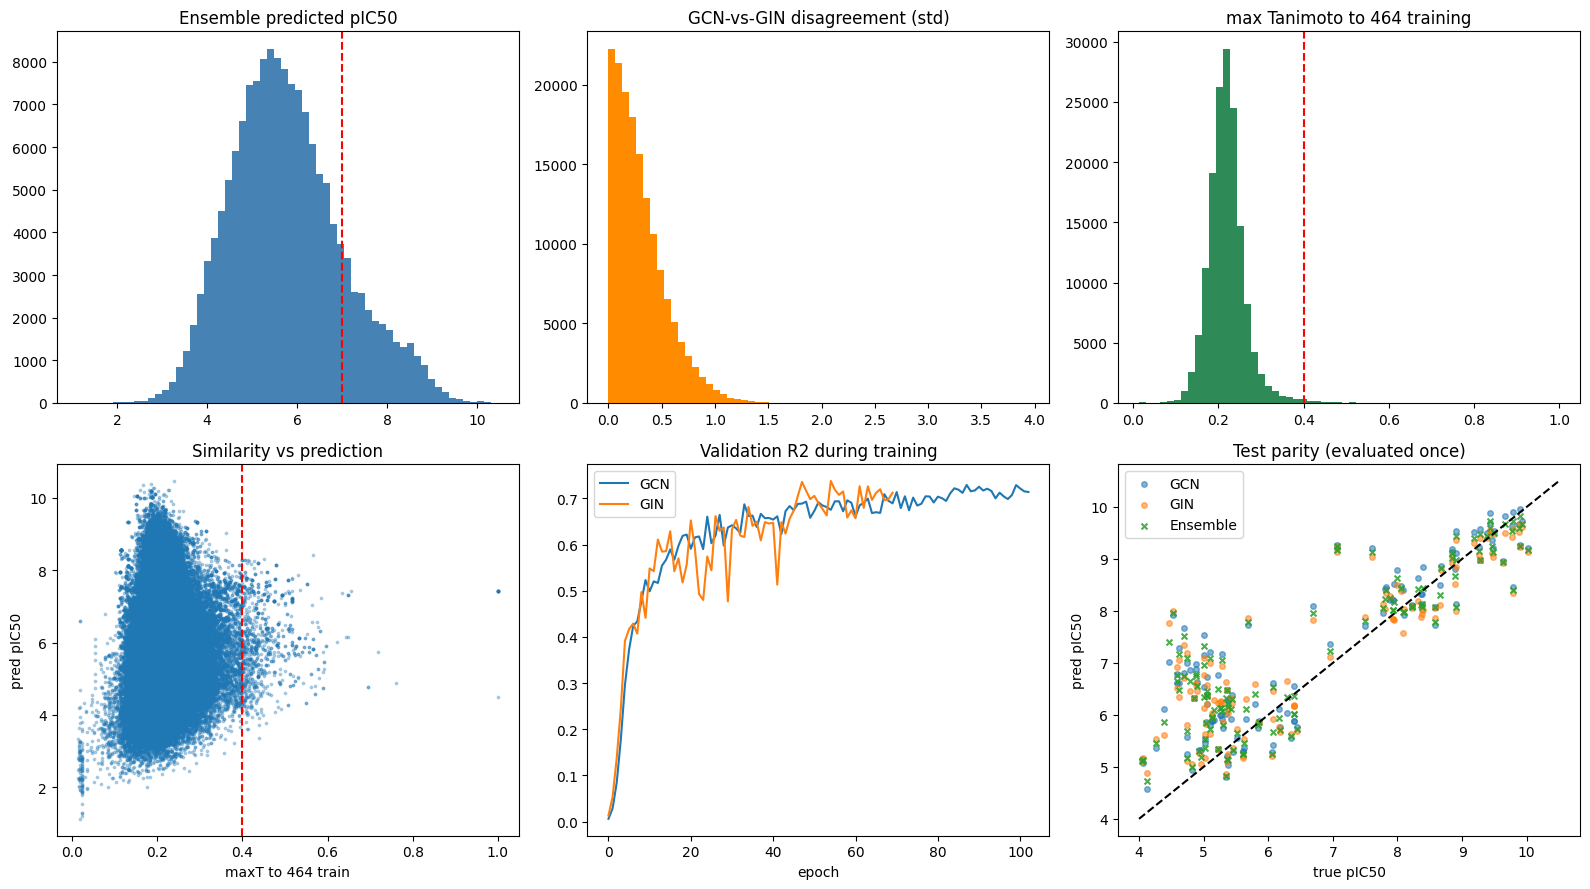

saved screening_regression_QC.png


In [17]:
# 16 — QC plots: prediction spread, uncertainty, AD and parity
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

v = lib['avg_pred_pic50'].dropna()
ax[0, 0].hist(v, bins=60, color='steelblue')
ax[0, 0].axvline(T1_CUT, color='red', ls='--')
ax[0, 0].set_title('Ensemble predicted pIC50')

ax[0, 1].hist(lib['std_pred_pic50'].dropna(), bins=60, color='darkorange')
ax[0, 1].set_title('GCN-vs-GIN disagreement (std)')

ax[0, 2].hist(lib['maxT_464'].dropna(), bins=60, color='seagreen')
ax[0, 2].axvline(AD_CUT, color='red', ls='--')
ax[0, 2].set_title('max Tanimoto to 464 training')

ax[1, 0].scatter(lib['maxT_464'], lib['avg_pred_pic50'], s=3, alpha=0.3)
ax[1, 0].axvline(AD_CUT, color='red', ls='--')
ax[1, 0].set_xlabel('maxT to 464 train')
ax[1, 0].set_ylabel('pred pIC50')
ax[1, 0].set_title('Similarity vs prediction')

ax[1, 1].plot(METRICS['gcn']['hist'], label='GCN')
ax[1, 1].plot(METRICS['gin']['hist'], label='GIN')
ax[1, 1].set_title('Validation R2 during training')
ax[1, 1].set_xlabel('epoch')
ax[1, 1].legend()

ax[1, 2].scatter(preds_cache['y_test'], preds_cache['gcn_test'], s=16, alpha=0.55, label='GCN')
ax[1, 2].scatter(preds_cache['y_test'], preds_cache['gin_test'], s=16, alpha=0.55, label='GIN')
_ens_test = 0.5 * (preds_cache['gcn_test'] + preds_cache['gin_test'])
ax[1, 2].scatter(preds_cache['y_test'], _ens_test, s=18, alpha=0.85, label='Ensemble', marker='x')
_lo = min(float(preds_cache['y_test'].min()), 4.0)
_hi = max(float(preds_cache['y_test'].max()), 10.5)
ax[1, 2].plot([_lo, _hi], [_lo, _hi], 'k--')
ax[1, 2].set_xlabel('true pIC50')
ax[1, 2].set_ylabel('pred pIC50')
ax[1, 2].set_title('Test parity (evaluated once)')
ax[1, 2].legend()

plt.tight_layout()
plt.savefig('screening_regression_QC.png', dpi=120)
plt.show()
print('saved screening_regression_QC.png')


In [18]:
# 17 — Acceptance report + run manifest (resume-safe)
import os, json, time, torch

def _met(y, p):
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    r2 = 1.0 - float(((y - p) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12))
    return dict(r2=round(r2, 4), rmse=round(float(np.sqrt(((y - p) ** 2).mean())), 4),
                mae=round(float(np.abs(y - p).mean()), 4))

_ens_val = 0.5 * (preds_cache['gcn_val'] + preds_cache['gin_val'])
_ens_test = 0.5 * (preds_cache['gcn_test'] + preds_cache['gin_test'])
METRICS['ensemble'] = dict(val=_met(preds_cache['y_val'], _ens_val),
                           test=_met(preds_cache['y_test'], _ens_test), hist=[])

manifest = {
    'run_utc': time.strftime('%Y-%m-%d %H:%M:%S', time.gmtime()),
    'config': dict(seed=RANDOM_SEED, morgan_radius=MORGAN_RADIUS, morgan_nbits=MORGAN_NBITS,
                   ad_cut=AD_CUT, t1_cut=T1_CUT, t2_cut=T2_CUT, hidden=GNN_HIDDEN,
                   layers=GNN_LAYERS, epochs_cap=GNN_EPOCHS, patience=GNN_PATIENCE,
                   batch=GNN_BATCH, resume=RESUME, dual_gpu=bool(USE_DUAL_GPU)),
    'split': dict(train=int(len(tr)), val=int(len(va)), test=int(len(te))),
    'library': dict(path=LIB_PATH, rows=int(len(lib)), hash=LIB_HASH),
    'metrics': {k: METRICS[k] for k in ['baseline', 'gcn', 'gin', 'ensemble']},
    'ad': dict(reference='maxT_464 >= AD_CUT', in_AD=int(lib['in_AD'].sum()),
               fraction=round(float(lib['in_AD'].mean()), 4),
               in_AD_all645=int(lib['in_AD_all645'].sum())),
    'tiers': lib['tier'].value_counts().to_dict(),
    'gpu': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    'pretrained_classifier_used': False,
}
json.dump(manifest, open('run_manifest.json', 'w'), indent=2)

print('=== ACCEPTANCE ===')
print('split train/val/test = %d/%d/%d | scaffold split + canonical-overlap assert (leak-check)' % (len(tr), len(va), len(te)))
print('library rows: %d | hash %s | source %s' % (len(lib), LIB_HASH, LIB_PATH))
print('coverage: GCN %d | GIN %d | maxT_464 %d | in_AD %d'
      % (int(lib['pred_gcn_pic50'].notna().sum()), int(lib['pred_gin_pic50'].notna().sum()),
         int(lib['maxT_464'].notna().sum()), int(lib['in_AD'].sum())))
print('AD reference = 464 training compounds | secondary column in_AD_all645')
print('test evaluated ONCE | early stopping only on val | no test-based model selection')
print('pretrained Part_18 .pth NOT used (temperature calibrated on test 129 => leakage)')
print('GPU:', manifest['gpu'], '| dual-gpu threads used:', bool(USE_DUAL_GPU and torch.cuda.device_count() > 1))
print('')
print('Regression metrics (pIC50):')
for nm, key in [('Ridge baseline', 'baseline'), ('GCN-reg', 'gcn'), ('GIN-reg', 'gin'), ('Ensemble', 'ensemble')]:
    v, t = METRICS[key]['val'], METRICS[key]['test']
    print('  %-15s val R2=%.3f RMSE=%.3f | test R2=%.3f RMSE=%.3f MAE=%.3f'
          % (nm, v['r2'], v['rmse'], t['r2'], t['rmse'], t['mae']))
print('')
for f in ['screening_full_regression.csv', 'hits_T1.csv', 'hits_T2.csv', 'hits_T3.csv',
          'screening_regression_QC.png', 'run_manifest.json']:
    if os.path.exists(f):
        print('  [out] %s (%.2f MB)' % (f, os.path.getsize(f) / 1e6))
print('cache:', sorted(os.listdir(CACHE_DIR)))
print('[done] re-run is safe: downloads, fingerprints, models, predictions and AD are cached and skipped.')


=== ACCEPTANCE ===
split train/val/test = 464/52/129 | scaffold split + canonical-overlap assert (leak-check)
library rows: 154587 | hash b4fed41f3afc | source ../Part_8/screening_results.csv
coverage: GCN 154587 | GIN 154587 | maxT_464 154587 | in_AD 886
AD reference = 464 training compounds | secondary column in_AD_all645
test evaluated ONCE | early stopping only on val | no test-based model selection
pretrained Part_18 .pth NOT used (temperature calibrated on test 129 => leakage)
GPU: [] | dual-gpu threads used: False

Regression metrics (pIC50):
  Ridge baseline  val R2=0.485 RMSE=1.174 | test R2=0.410 RMSE=1.412 MAE=1.273
  GCN-reg         val R2=0.861 RMSE=0.609 | test R2=0.649 RMSE=1.089 MAE=0.794
  GIN-reg         val R2=0.866 RMSE=0.599 | test R2=0.671 RMSE=1.055 MAE=0.773
  Ensemble        val R2=0.871 RMSE=0.587 | test R2=0.666 RMSE=1.063 MAE=0.768

  [out] screening_full_regression.csv (38.59 MB)
  [out] hits_T1.csv (0.02 MB)
  [out] hits_T2.csv (0.03 MB)
  [out] hits_T3.cs

In [19]:
# 18 — FULL INPUT/OUTPUT AUDIT: every DL input, prediction, residual and error
import os, json, numpy as np, pandas as pd, torch
from torch_geometric.loader import DataLoader as _AuditLoader

AUDIT = {'data': {}, 'models': {}, 'metrics': {}, 'checks': {}, 'screening': {}}
SPLITS = [('train', tr, train_graphs), ('val', va, val_graphs), ('test', te, test_graphs)]

print('=' * 82)
print('DEEP-LEARNING INPUT AUDIT (features, targets, model config, devices)')
print('=' * 82)
for nm, ii, gs in SPLITS:
    yt = np.asarray(raw_targets)[ii]
    ns = np.array([int(g.num_nodes) for g in gs])
    es = np.array([int(g.num_edges) for g in gs])
    print('%-5s n=%3d | pIC50 min/mean/max %.3f / %.3f / %.3f | nodes %.1f+-%.1f | edges %.1f+-%.1f'
          % (nm, len(gs), yt.min(), yt.mean(), yt.max(), ns.mean(), ns.std(), es.mean(), es.std()))
    AUDIT['data'][nm] = dict(n=int(len(gs)), pic50_min=float(yt.min()), pic50_mean=float(yt.mean()),
                             pic50_max=float(yt.max()), nodes_mean=float(ns.mean()), edges_mean=float(es.mean()))

g0 = train_graphs[0]
print('node feature dim: %d | edge_index: 2 x %d | target = scaled delta'
      % (int(g0.x.shape[1]), int(g0.edge_index.shape[1])))
print('sample INPUT (train graph 0) y_scaled = %.4f' % float(g0.y.view(-1)[0]))
print('  x.shape', tuple(g0.x.shape), '| first 3 atom feature rows:')
print(g0.x[:3].numpy())
print('  edge_index[:, :5]:')
print(g0.edge_index[:, :5].numpy())
print('delta scaler: mean %.4f | scale %.4f (fit on 464 train only)'
      % (float(scaler.mean_[0]), float(scaler.scale_[0])))
print('model config: hidden=%d layers=%d batch=%d lr=%g wd=%g patience=%d'
      % (GNN_HIDDEN, GNN_LAYERS, GNN_BATCH, GNN_LR, GNN_WD, GNN_PATIENCE))
print('devices: dev0=%s | dev1=%s | cuda=%s | n_gpu=%d'
      % (dev0, dev1, torch.cuda.is_available(), torch.cuda.device_count()))
print('policy: 464 train / 52 val / 129 test | early stopping = val only | test scored once')

print('')
print('=' * 82)
print('MODEL LOAD AUDIT (strict load, finite weights, parameter count)')
print('=' * 82)
MODELS, RAW_PRED = {}, {}
for kind in ['gcn', 'gin']:
    path = os.path.join(CACHE_DIR, kind + '_reg.pt')
    model = GNNReg(kind=kind)
    sd = torch_load_compat(path)
    model.load_state_dict(sd)
    dev = dev0 if kind == 'gcn' else dev1
    model.to(dev).eval()
    nonfinite = sum(int((~torch.isfinite(v)).sum().item()) for v in model.state_dict().values())
    MODELS[kind] = (model, dev)
    print('%s: params %d | state_dict tensors %d | non-finite weights %d | device %s'
          % (kind.upper(), count_params(model), len(sd), nonfinite, dev))
    print(model)
    RAW_PRED[kind] = {}
    for nm, ii, gs in SPLITS:
        dl = _AuditLoader(gs, batch_size=SCREEN_BATCH, shuffle=False, num_workers=0)
        out = []
        with torch.no_grad():
            for b in dl:
                b = b.to(dev)
                out.append(model(b.x, b.edge_index, b.batch).detach().cpu().numpy())
        RAW_PRED[kind][nm] = np.concatenate(out)
    AUDIT['models'][kind] = dict(params=int(count_params(model)), state_tensors=int(len(sd)),
                                  nonfinite_weights=int(nonfinite), device=str(dev))

def _audit_inv(p_scaled, idx):
    d = scaler.inverse_transform(np.asarray(p_scaled).reshape(-1, 1)).ravel()
    return np.clip(d + base_all[np.asarray(idx)], 0.0, 12.0)

PIC50 = {k: {nm: _audit_inv(RAW_PRED[k][nm], ii) for nm, ii, _ in SPLITS} for k in ['gcn', 'gin']}
max_saved_diff = 0.0
for kind in ['gcn', 'gin']:
    for nm in ['val', 'test']:
        saved = preds_cache.get(kind + '_' + nm)
        if saved is not None:
            d = float(np.max(np.abs(np.asarray(saved) - PIC50[kind][nm])))
            max_saved_diff = max(max_saved_diff, d)
            print('recompute-vs-saved %s %s: max|diff| = %.2e' % (kind, nm, d))

rows = []
for nm, ii, gs in SPLITS:
    for j, i in enumerate(ii):
        i = int(i)
        rows.append(dict(split=nm, row_index=i, identifier=str(train_ids[i]), smiles=str(smiles_train[i]),
                         pIC50_true=float(raw_targets[i]), pIC50_baseline=float(base_all[i]),
                         pIC50_gcn=float(PIC50['gcn'][nm][j]), pIC50_gin=float(PIC50['gin'][nm][j])))
audit = pd.DataFrame(rows)
audit['pIC50_ensemble'] = (audit.pIC50_gcn + audit.pIC50_gin) / 2.0
for c in ['gcn', 'gin', 'ensemble']:
    audit['resid_' + c] = audit.pIC50_true - audit['pIC50_' + c]
    audit['abs_err_' + c] = audit['resid_' + c].abs()
audit.to_csv('dl_full_predictions.csv', index=False)
print('full prediction table:', audit.shape, '-> dl_full_predictions.csv')

def _audit_metrics(t, p):
    t = np.asarray(t, float)
    p = np.asarray(p, float)
    resid = t - p
    ss_res = float((resid ** 2).sum())
    ss_tot = float(((t - t.mean()) ** 2).sum())
    slope, intercept = np.polyfit(t, p, 1)
    return dict(n=int(len(t)), r2=float(1 - ss_res / max(ss_tot, 1e-12)),
                rmse=float(np.sqrt((resid ** 2).mean())), mae=float(np.abs(resid).mean()),
                bias=float(resid.mean()), resid_std=float(resid.std()),
                cal_slope=float(slope), cal_intercept=float(intercept),
                max_abs=float(np.abs(resid).max()), pred_min=float(p.min()), pred_max=float(p.max()))

print('')
print('=' * 82)
print('OUTPUT / ERROR AUDIT (pIC50; residual = true - predicted)')
print('=' * 82)
print('%-6s %-8s %4s %7s %7s %7s %8s %9s %9s %9s %8s'
      % ('split', 'model', 'n', 'R2', 'RMSE', 'MAE', 'bias', 'resid_sd', 'max|err|', 'cal_slope', 'cal_int'))
for nm, ii, gs in SPLITS:
    t = raw_targets[ii]
    ens = (PIC50['gcn'][nm] + PIC50['gin'][nm]) / 2.0
    for label, p in [('Ridge', base_all[ii]), ('GCN', PIC50['gcn'][nm]),
                     ('GIN', PIC50['gin'][nm]), ('ENS', ens)]:
        m = _audit_metrics(t, p)
        AUDIT['metrics']['%s_%s' % (nm, label)] = m
        print('%-6s %-8s %4d %7.3f %7.3f %7.3f %8.3f %9.3f %9.3f %9.3f %8.2f'
              % (nm, label, m['n'], m['r2'], m['rmse'], m['mae'], m['bias'], m['resid_std'],
                 m['max_abs'], m['cal_slope'], m['cal_intercept']))

print('')
print('TRAINING HISTORY — every epoch (model selected by best val R2)')
max_ep = max(len(METRICS['gcn']['hist']), len(METRICS['gin']['hist']))
hdf = pd.DataFrame({'epoch': np.arange(1, max_ep + 1)})
for kind in ['gcn', 'gin']:
    h = METRICS[kind]['hist']
    hdf[kind + '_val_r2'] = pd.Series(h)
    best_ep = int(np.argmax(h)) + 1
    print('%s: %d epochs | best epoch %d | best val R2 %.4f | params %d'
          % (kind.upper(), len(h), best_ep, max(h), METRICS[kind]['params']))
    for ep, r2 in enumerate(h, 1):
        print('  %s ep %03d  val_R2 %.4f%s' % (kind, ep, r2, '  <= BEST' if ep == best_ep else ''))
hdf.to_csv('dl_training_history.csv', index=False)

pd.set_option('display.max_rows', 400)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 46)
show = audit.copy()
show['smiles'] = show['smiles'].str.slice(0, 46)
cols = ['split', 'identifier', 'smiles', 'pIC50_true', 'pIC50_baseline', 'pIC50_gcn',
        'pIC50_gin', 'pIC50_ensemble', 'resid_gcn', 'resid_gin', 'resid_ensemble']
print('')
print('FULL 645-ROW OUTPUT TABLE (train + val + test; every compound, every prediction)')
print('NOTE: train rows are in-sample (fit data), not accuracy estimates; val/test rows are held out.')
print(show[cols].round(3).to_string(index=False))

print('')
print('WORST 8 ABSOLUTE ERRORS PER SPLIT (ensemble)')
for nm in ['train', 'val', 'test']:
    sub = audit[audit.split == nm].nlargest(8, 'abs_err_ensemble').copy()
    sub['smiles'] = sub['smiles'].str.slice(0, 42)
    print('-- %s --' % nm)
    print(sub[['identifier', 'smiles', 'pIC50_true', 'pIC50_gcn', 'pIC50_gin',
               'pIC50_ensemble', 'resid_ensemble']].round(3).to_string(index=False))

print('')
print('SIGNED BIAS BY TRUE pIC50 BIN (ensemble; negative = over-prediction)')
audit['true_bin'] = pd.cut(audit.pIC50_true, bins=[0, 6, 7, 8, 9, 12])
print(audit.groupby(['split', 'true_bin'], observed=True)['resid_ensemble']
      .agg(['count', 'mean']).round(3).to_string())

print('')
print('=' * 82)
print('SCREENING INPUT/OUTPUT AUDIT (SMILES -> graph -> prediction -> saved CSV)')
print('=' * 82)
SPATH = 'screening_full_regression.csv'
if os.path.exists(SPATH):
    scr = pd.read_csv(SPATH)
    print('rows %d | columns %d | pred_gcn non-null %d | pred_gin non-null %d | maxT_464 non-null %d'
          % (len(scr), scr.shape[1], int(scr.pred_gcn_pic50.notna().sum()),
             int(scr.pred_gin_pic50.notna().sum()), int(scr.maxT_464.notna().sum())))
    print('range: GCN %.2f..%.2f | GIN %.2f..%.2f | ENS %.2f..%.2f | std %.3f..%.3f'
          % (scr.pred_gcn_pic50.min(), scr.pred_gcn_pic50.max(), scr.pred_gin_pic50.min(),
             scr.pred_gin_pic50.max(), scr.avg_pred_pic50.min(), scr.avg_pred_pic50.max(),
             scr.std_pred_pic50.min(), scr.std_pred_pic50.max()))
    print('in_AD %d (%.2f%%) | tiers %s'
          % (int(scr.in_AD.sum()), 100.0 * float(scr.in_AD.mean()),
             {str(k): int(v) for k, v in scr.tier.value_counts().items()}))

    chk = {}
    chk['screening_coverage'] = bool(scr.pred_gcn_pic50.notna().all() and scr.pred_gin_pic50.notna().all())
    chk['screening_predictions_finite'] = bool(np.isfinite(scr[['pred_gcn_pic50', 'pred_gin_pic50']].values).all())
    chk['screening_pred_in_0_12'] = bool(((scr.pred_gcn_pic50 >= 0) & (scr.pred_gcn_pic50 <= 12)).all()
                                         and ((scr.pred_gin_pic50 >= 0) & (scr.pred_gin_pic50 <= 12)).all())
    chk['avg_is_mean_of_two'] = bool(np.allclose(scr.avg_pred_pic50,
                                                 (scr.pred_gcn_pic50 + scr.pred_gin_pic50) / 2.0, atol=1e-6))
    chk['in_AD_flag_consistent'] = bool((scr.in_AD == (scr.maxT_464 >= AD_CUT)).all())
    chk['tier_values_valid'] = bool(scr.tier.isin(['T1', 'T2', 'T3']).all())

    pick = pd.concat([
        scr.nlargest(2, 'avg_pred_pic50'),
        scr[scr.in_AD].nlargest(2, 'avg_pred_pic50'),
        scr[scr.in_AD].sample(1, random_state=RANDOM_SEED),
    ]).drop_duplicates(subset=['identifier', 'canonical_smiles']).head(5)
    print('spot-check: rebuilding graph + re-predicting %d saved rows' % len(pick))
    spot_rows = []
    for _, r in pick.iterrows():
        g = mol_to_graph(r['canonical_smiles'], 0.0)
        d = rdkit_desc(r['canonical_smiles'])
        base = 0.0 if d is None else float(baseline_model.predict(np.asarray([d], dtype=float))[0])
        vals = {}
        for kind in ['gcn', 'gin']:
            model, dev = MODELS[kind]
            if g is None:
                vals[kind] = float('nan')
                continue
            gg = g.to(dev)
            batch = torch.zeros(gg.num_nodes, dtype=torch.long, device=dev)
            with torch.no_grad():
                ps = float(model(gg.x, gg.edge_index, batch).item())
            vals[kind] = float(np.clip(scaler.inverse_transform([[ps]])[0, 0] + base, 0.0, 12.0))
        spot_rows.append(dict(identifier=r['identifier'], smiles=str(r['canonical_smiles'])[:40],
                              saved_gcn=float(r['pred_gcn_pic50']), recomputed_gcn=vals['gcn'],
                              saved_gin=float(r['pred_gin_pic50']), recomputed_gin=vals['gin'],
                              max_abs_diff=max(abs(vals['gcn'] - float(r['pred_gcn_pic50'])),
                                               abs(vals['gin'] - float(r['pred_gin_pic50'])))))
    spot = pd.DataFrame(spot_rows)
    print(spot.round(3).to_string(index=False))
    chk['screening_recompute_match'] = bool(spot.max_abs_diff.max() < 1e-3)
    AUDIT['checks'].update(chk)
    AUDIT['screening'] = dict(rows=int(len(scr)), in_AD=int(scr.in_AD.sum()),
                              tiers={str(k): int(v) for k, v in scr.tier.value_counts().items()},
                              spotcheck=json.loads(spot.round(6).to_json(orient='records')))
else:
    print('[skip] screening_full_regression.csv not found')

AUDIT['checks']['graph_counts_match_split'] = bool(len(train_graphs) == len(tr)
                                                   and len(val_graphs) == len(va)
                                                   and len(test_graphs) == len(te))
AUDIT['checks']['split_464_52_129'] = bool(len(tr) == 464 and len(va) == 52 and len(te) == 129)
AUDIT['checks']['full_table_rows_645'] = bool(len(audit) == 645)
AUDIT['checks']['all_predictions_finite'] = bool(np.isfinite(audit[['pIC50_gcn', 'pIC50_gin']].values).all())
AUDIT['checks']['model_weights_finite'] = bool(all(AUDIT['models'][k]['nonfinite_weights'] == 0
                                                   for k in ['gcn', 'gin']))
AUDIT['checks']['recompute_matches_saved'] = bool(max_saved_diff < 1e-6)

print('')
print('=' * 82)
print('AUDIT SUMMARY (PASS/FAIL)')
print('=' * 82)
for k, v in AUDIT['checks'].items():
    print('%-32s %s' % (k, 'PASS' if v else 'FAIL'))
print('')
print('INTERPRETATION: R2/RMSE/MAE above are the honest test errors (test scored once).')
print('Residual bias near 0 = no systematic over/under-prediction; cal_slope near 1 = calibrated.')
print('Library predictions are extrapolation for most rows — always filter with in_AD.')
json.dump(AUDIT, open('dl_audit.json', 'w'), indent=2)
for f in ['dl_full_predictions.csv', 'dl_training_history.csv', 'dl_audit.json']:
    print('  [out] %s (%.2f MB)' % (f, os.path.getsize(f) / 1e6))
print('[done] full DL input/output audit saved. Every row is in dl_full_predictions.csv.')


DEEP-LEARNING INPUT AUDIT (features, targets, model config, devices)
train n=464 | pIC50 min/mean/max 3.757 / 7.253 / 10.229 | nodes 35.5+-5.1 | edges 78.6+-11.8
val   n= 52 | pIC50 min/mean/max 3.599 / 7.208 / 9.810 | nodes 34.6+-5.2 | edges 76.9+-11.5
test  n=129 | pIC50 min/mean/max 4.053 / 6.672 / 10.013 | nodes 32.5+-4.4 | edges 71.4+-9.4
node feature dim: 78 | edge_index: 2 x 86 | target = scaled delta
sample INPUT (train graph 0) y_scaled = 0.7866
  x.shape (39, 78) | first 3 atom feature rows:
[[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.
  1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1.
  0. 0. 0. 0. 0. 0.]
 [0. 0.

GIN: params 126465 | state_dict tensors 34 | non-finite weights 0 | device cpu
GNNReg(
  (convs): ModuleList(
    (0): GINConv(nn=Sequential(
      (0): Linear(in_features=78, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    ))
    (1-2): 2 x GINConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    ))
  )
  (bns): ModuleList(
    (0-2): 3 x BatchNorm(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (head): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


recompute-vs-saved gcn val: max|diff| = 0.00e+00
recompute-vs-saved gcn test: max|diff| = 1.19e-07
recompute-vs-saved gin val: max|diff| = 0.00e+00
recompute-vs-saved gin test: max|diff| = 2.98e-08
full prediction table: (645, 15) -> dl_full_predictions.csv

OUTPUT / ERROR AUDIT (pIC50; residual = true - predicted)
split  model       n      R2    RMSE     MAE     bias  resid_sd  max|err| cal_slope  cal_int
train  Ridge     464   0.450   1.095   0.896   -0.000     1.095     3.638     0.450     3.99
train  GCN       464   0.851   0.570   0.390   -0.172     0.543     2.838     0.859     1.19
train  GIN       464   0.858   0.556   0.385   -0.097     0.547     2.682     0.819     1.41
train  ENS       464   0.861   0.551   0.375   -0.134     0.534     2.760     0.839     1.30
val    Ridge      52   0.485   1.174   0.966    0.090     1.170     2.721     0.450     3.88
val    GCN        52   0.861   0.609   0.436   -0.098     0.601     1.805     0.861     1.10
val    GIN        52   0.866   0

rows 154587 | columns 17 | pred_gcn non-null 154587 | pred_gin non-null 154587 | maxT_464 non-null 154587
range: GCN 1.32..10.49 | GIN 0.94..11.04 | ENS 1.13..10.46 | std 0.000..3.943
in_AD 886 (0.57%) | tiers {'T3': 129583, 'T2': 24901, 'T1': 103}
spot-check: rebuilding graph + re-predicting 5 saved rows
  identifier                                   smiles  saved_gcn  recomputed_gcn  saved_gin  recomputed_gin  max_abs_diff
CNP0422481.1 CC[C@@H](C)[C@H](C)[C@@H](O)[C@H](O)[C@@      9.891           9.891     11.037          11.037           0.0
CNP0557594.1 CC[C@@H](C)CC[C@H](O[C@@H]1O[C@H](CO)[C@     10.485          10.485     10.265          10.265           0.0
CNP0423424.1 NC1=NC(=O)N([C@@H]2O[C@H](C(=O)O)[C@@H](      8.467           8.467      8.372           8.372           0.0
CNP0071615.1 CCC(=O)N[C@@H](CC1=CC=C(O)C=C1)C(=O)N[C@      8.340           8.340      8.257           8.257           0.0
CNP0240189.1 N[C@@H](CCC(=O)N[C@@H](CC1=CC=C(O)C=C1)C      6.825           6.825   